In [10]:
# ── CONFIGURACION DE RUTA ────────────────────────────────────────────
# Ajusta PROJECT_ROOT a la carpeta raiz de tu repositorio
# ─────────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

PROJECT_ROOT = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita aqui

# Agrega src/ al path para poder importar config
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Verifica que la ruta es correcta
assert PROJECT_ROOT.exists(), f'Ruta no encontrada: {PROJECT_ROOT}'
assert (SRC / 'config.py').exists(), 'No se encontro src/config.py — ejecuta primero 00_entorno.ipynb'
print(f'OK: {PROJECT_ROOT}')

OK: D:\Documentos\GitHub\dengue


# 02b · Regresion Logistica Clinica — OR Ajustados
**Fase:** Analisis multivariado explicativo

Se comparan 4 modelos anidados:
- **M1:** Solo signos de alarma
- **M2:** Signos + sintomas generales
- **M3:** M1 + variables sociodemograficas
- **M4:** M2 + sociodemograficas (modelo completo)

> **Distincion clave:** Estos son modelos **explicativos** (OR con IC95%).
> Los modelos **predictivos** (F1, AUC) estan en el notebook 03.

In [11]:
# import subprocess, sys
#subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scipy==1.11.4'])
# Reiniciar kernel después

In [12]:
import sys
sys.path.insert(0, '../../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import joblib
import warnings
from scipy import stats
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import config
from config import (DATA_INTERIM, OUT_FIGURES, OUT_TABLES, CHECKPOINTS,
    COLORS, TARGET_COL, SIGNOS_ALARMA, SINTOMAS_GENERALES)

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})

df_con = joblib.load(DATA_INTERIM / 'datos_con_signos.pkl')
print(f'DCSA cargado: {df_con.shape[0]:,} registros')
print(f'Hospitalizacion: {df_con[TARGET_COL].mean():.1%}')

DCSA cargado: 12,713 registros
Hospitalizacion: 64.8%


In [13]:
# Preparacion de variables
# Recodificar clinicas: 1=presente, 0=ausente (era 1/2 en SIVIGILA)
todas     = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo = [v for v in ['SEXO_','DEF_CLAS_EDAD','TIP_SS_','ESTRATO_']
             if v in df_con.columns]

def prep(df, clinicas, demos=None):
    cols = clinicas + [TARGET_COL] + (demos or [])
    # Solo incluir columnas que existen
    cols = [c for c in cols if c in df.columns]
    out  = df[cols].copy()
    
    # Recodificar clínicas
    for v in clinicas:
        out[v] = pd.to_numeric(out[v], errors='coerce').map({1: 1.0, 2: 0.0})
    
    # Convertir todo a float64 — incluyendo demos categóricas
    for col in out.columns:
        if col in (demos or []):
            # Categóricas: convertir a códigos numéricos
            out[col] = pd.Categorical(out[col]).codes.astype(np.float64)
            out[col] = out[col].replace(-1, np.nan)  # -1 = NaN en Categorical
        else:
            out[col] = pd.to_numeric(out[col], errors='coerce').astype(np.float64)
    
    antes = len(out)
    out   = out.dropna()
    print(f'  {len(out):,} filas válidas de {antes:,} ({len(out)/antes:.1%})')
    return out

df_m1 = prep(df_con, SIGNOS_ALARMA)
df_m2 = prep(df_con, todas)
df_m3 = prep(df_con, SIGNOS_ALARMA, vars_demo)
df_m4 = prep(df_con, todas,         vars_demo)
print(f'M1:{len(df_m1):,}  M2:{len(df_m2):,}  M3:{len(df_m3):,}  M4:{len(df_m4):,}')

  12,713 filas válidas de 12,713 (100.0%)
  12,713 filas válidas de 12,713 (100.0%)
  12,713 filas válidas de 12,713 (100.0%)
  12,713 filas válidas de 12,713 (100.0%)
M1:12,713  M2:12,713  M3:12,713  M4:12,713


In [14]:
def logit_con_OR(df, clinicas, demos=None):
    """
    Regresion logistica sin statsmodels (incompatible con scipy>=1.12).
    Usa sklearn para el ajuste y calcula OR, IC95% y p-valores de Wald
    a partir de la matriz de informacion de Fisher — equivalente a statsmodels.
    C=1e6 elimina la regularizacion L2 para obtener coeficientes ML puros.
    """
    predictores = list(clinicas) + (demos or [])
    X = df[predictores].values.astype(np.float64)
    y = df[TARGET_COL].values.astype(np.float64)

    modelo = LogisticRegression(
        max_iter=1000, C=1e6, solver='lbfgs', random_state=42)
    modelo.fit(X, y)
    coefs = modelo.coef_[0]

    # Matriz de covarianza via Fisher information
    p_hat  = modelo.predict_proba(X)[:, 1]
    W      = p_hat * (1 - p_hat)
    X_b    = np.column_stack([np.ones(len(X)), X])
    try:
        cov    = np.linalg.inv(X_b.T * W @ X_b)
        se     = np.sqrt(np.diag(cov)[1:])
    except np.linalg.LinAlgError:
        se = np.full(len(coefs), np.nan)

    OR     = np.exp(coefs)
    IC_inf = np.exp(coefs - 1.96 * se)
    IC_sup = np.exp(coefs + 1.96 * se)
    z      = coefs / se
    pvals  = 2 * (1 - stats.norm.cdf(np.abs(z)))

    # Pseudo R2 de McFadden y AIC
    eps      = 1e-15
    ll_m     = np.sum(y*np.log(p_hat+eps) + (1-y)*np.log(1-p_hat+eps))
    p0       = y.mean()
    ll_0     = np.sum(y*np.log(p0) + (1-y)*np.log(1-p0))
    pseudo_r2 = 1 - ll_m / ll_0
    k        = len(coefs) + 1
    aic      = -2*ll_m + 2*k
    bic      = -2*ll_m + k*np.log(len(y))

    tabla = pd.DataFrame({
        'Variable': predictores,
        'OR':       OR.round(3),
        'IC95_inf': IC_inf.round(3),
        'IC95_sup': IC_sup.round(3),
        'p_valor':  pvals.round(5),
        'Sig':      ['***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else ''))
                     for p in pvals],
        'Tipo':     ['Signo de alarma' if v in SIGNOS_ALARMA
                     else ('Sintoma general' if v in SINTOMAS_GENERALES else 'Demografica')
                     for v in predictores],
    })
    # Guardar metricas como atributos
    tabla.attrs.update({
        'aic': round(aic,2), 'bic': round(bic,2),
        'pseudo_r2': round(pseudo_r2,4),
        'll_modelo': ll_m, 'll_nulo': ll_0,
        'n_vars': len(coefs), 'n_obs': len(y),
        'modelo_sklearn': modelo,
    })
    return tabla

# Ajustar los 4 modelos
resultados = {}
for nombre, df_in, clinicas, demos in [
    ('M1_signos',   df_m1, SIGNOS_ALARMA, None),
    ('M2_todas',    df_m2, todas,         None),
    ('M3_sig_demo', df_m3, SIGNOS_ALARMA, vars_demo),
    ('M4_completo', df_m4, todas,         vars_demo),
]:
    t = logit_con_OR(df_in, clinicas, demos)
    resultados[nombre] = t
    print(f"{nombre}: AIC={t.attrs['aic']:.1f} | Pseudo-R2={t.attrs['pseudo_r2']:.3f}")

print('\nOR ajustados — M4 (modelo completo):')
display(resultados['M4_completo'][['Variable','Tipo','OR','IC95_inf','IC95_sup','p_valor','Sig']])

M1_signos: AIC=14130.6 | Pseudo-R2=0.144
M2_todas: AIC=13812.7 | Pseudo-R2=0.164
M3_sig_demo: AIC=13747.2 | Pseudo-R2=0.168
M4_completo: AIC=13410.8 | Pseudo-R2=0.189

OR ajustados — M4 (modelo completo):


,Variable,Tipo,OR,IC95_inf,IC95_sup,p_valor,Sig
0,FIEBRE,Sintoma general,3.723,2.875,4.821,0.00000,***
1,CEFALEA,Sintoma general,0.728,0.614,0.863,0.00025,***
2,DOLRRETROO,Sintoma general,1.042,0.924,1.175,0.50571,
3,MALGIAS,Sintoma general,1.207,1.018,1.431,0.03034,*
4,ARTRALGIA,Sintoma general,1.207,1.058,1.376,0.00513,**
5,ERUPCIONR,Sintoma general,0.815,0.721,0.922,0.00109,**
6,DOLOR_ABDO,Signo de alarma,1.430,1.268,1.612,0.00000,***
7,VOMITO,Signo de alarma,1.154,1.017,1.309,0.02673,*
8,DIARREA,Signo de alarma,0.971,0.852,1.106,0.65484,
9,SOMNOLENCI,Signo de alarma,0.972,0.761,1.242,0.81949,


In [15]:
# Comparacion de modelos — LRT aproximado con log-likelihoods
tabla_comp = pd.DataFrame([
    {
        'Modelo': nombre,
        'N_vars': t.attrs['n_vars'],
        'N_obs':  t.attrs['n_obs'],
        'AIC':    t.attrs['aic'],
        'BIC':    t.attrs['bic'],
        'Pseudo_R2': t.attrs['pseudo_r2'],
    }
    for nombre, t in resultados.items()
])
display(tabla_comp)
tabla_comp.to_csv(OUT_TABLES / 'comparacion_modelos_logisticos.csv', index=False)

# LRT M1 vs M2: los sintomas generales aportan informacion adicional?
ll_m1  = resultados['M1_signos'].attrs['ll_modelo']
ll_m2  = resultados['M2_todas'].attrs['ll_modelo']
k_m1   = resultados['M1_signos'].attrs['n_vars']
k_m2   = resultados['M2_todas'].attrs['n_vars']
lr_stat = 2 * (ll_m2 - ll_m1)
p_lr    = chi2.sf(lr_stat, k_m2 - k_m1)
print(f'LRT M1 vs M2: LR={lr_stat:.2f}, df={k_m2-k_m1}, p={p_lr:.2e}')
print('=> Sintomas generales aportan informacion significativa' if p_lr < 0.05
    else '=> No mejoran significativamente el ajuste')

,Modelo,N_vars,N_obs,AIC,BIC,Pseudo_R2
0,M1_signos,11,12713,14130.60,14220.00,0.1443
1,M2_todas,17,12713,13812.73,13946.84,0.1643
2,M3_sig_demo,15,12713,13747.17,13866.38,0.1681
3,M4_completo,21,12713,13410.77,13574.68,0.1892


LRT M1 vs M2: LR=329.86, df=6, p=3.23e-68
=> Sintomas generales aportan informacion significativa


In [16]:
# Extraer OR ajustados del modelo M4 — solo variables clinicas
tabla_or = (
    resultados['M4_completo']
    [resultados['M4_completo']['Tipo'].isin(['Signo de alarma','Sintoma general'])]
    .copy()
)
tabla_or['p_fmt'] = tabla_or['p_valor'].apply(
    lambda x: f'{x:.2e}' if x < 0.001 else f'{x:.3f}')

display(tabla_or[['Variable','Tipo','OR','IC95_inf','IC95_sup','p_fmt','Sig']]
    .sort_values('OR', ascending=False))
tabla_or.to_csv(OUT_TABLES / 'OR_ajustados_M4_DCSA.csv', index=False)

,Variable,Tipo,OR,IC95_inf,IC95_sup,p_fmt,Sig
0,FIEBRE,Sintoma general,3.723,2.875,4.821,0.00e+00,***
15,CAIDA_PLAQ,Signo de alarma,2.648,2.326,3.014,0.00e+00,***
6,DOLOR_ABDO,Signo de alarma,1.430,1.268,1.612,0.00e+00,***
12,HEM_MUCOSA,Signo de alarma,1.411,1.116,1.783,0.004,**
16,ACUM_LIQUI,Signo de alarma,1.321,0.774,2.256,0.307,
4,ARTRALGIA,Sintoma general,1.207,1.058,1.376,0.005,**
3,MALGIAS,Sintoma general,1.207,1.018,1.431,0.030,*
7,VOMITO,Signo de alarma,1.154,1.017,1.309,0.027,*
2,DOLRRETROO,Sintoma general,1.042,0.924,1.175,0.506,
9,SOMNOLENCI,Signo de alarma,0.972,0.761,1.242,0.819,


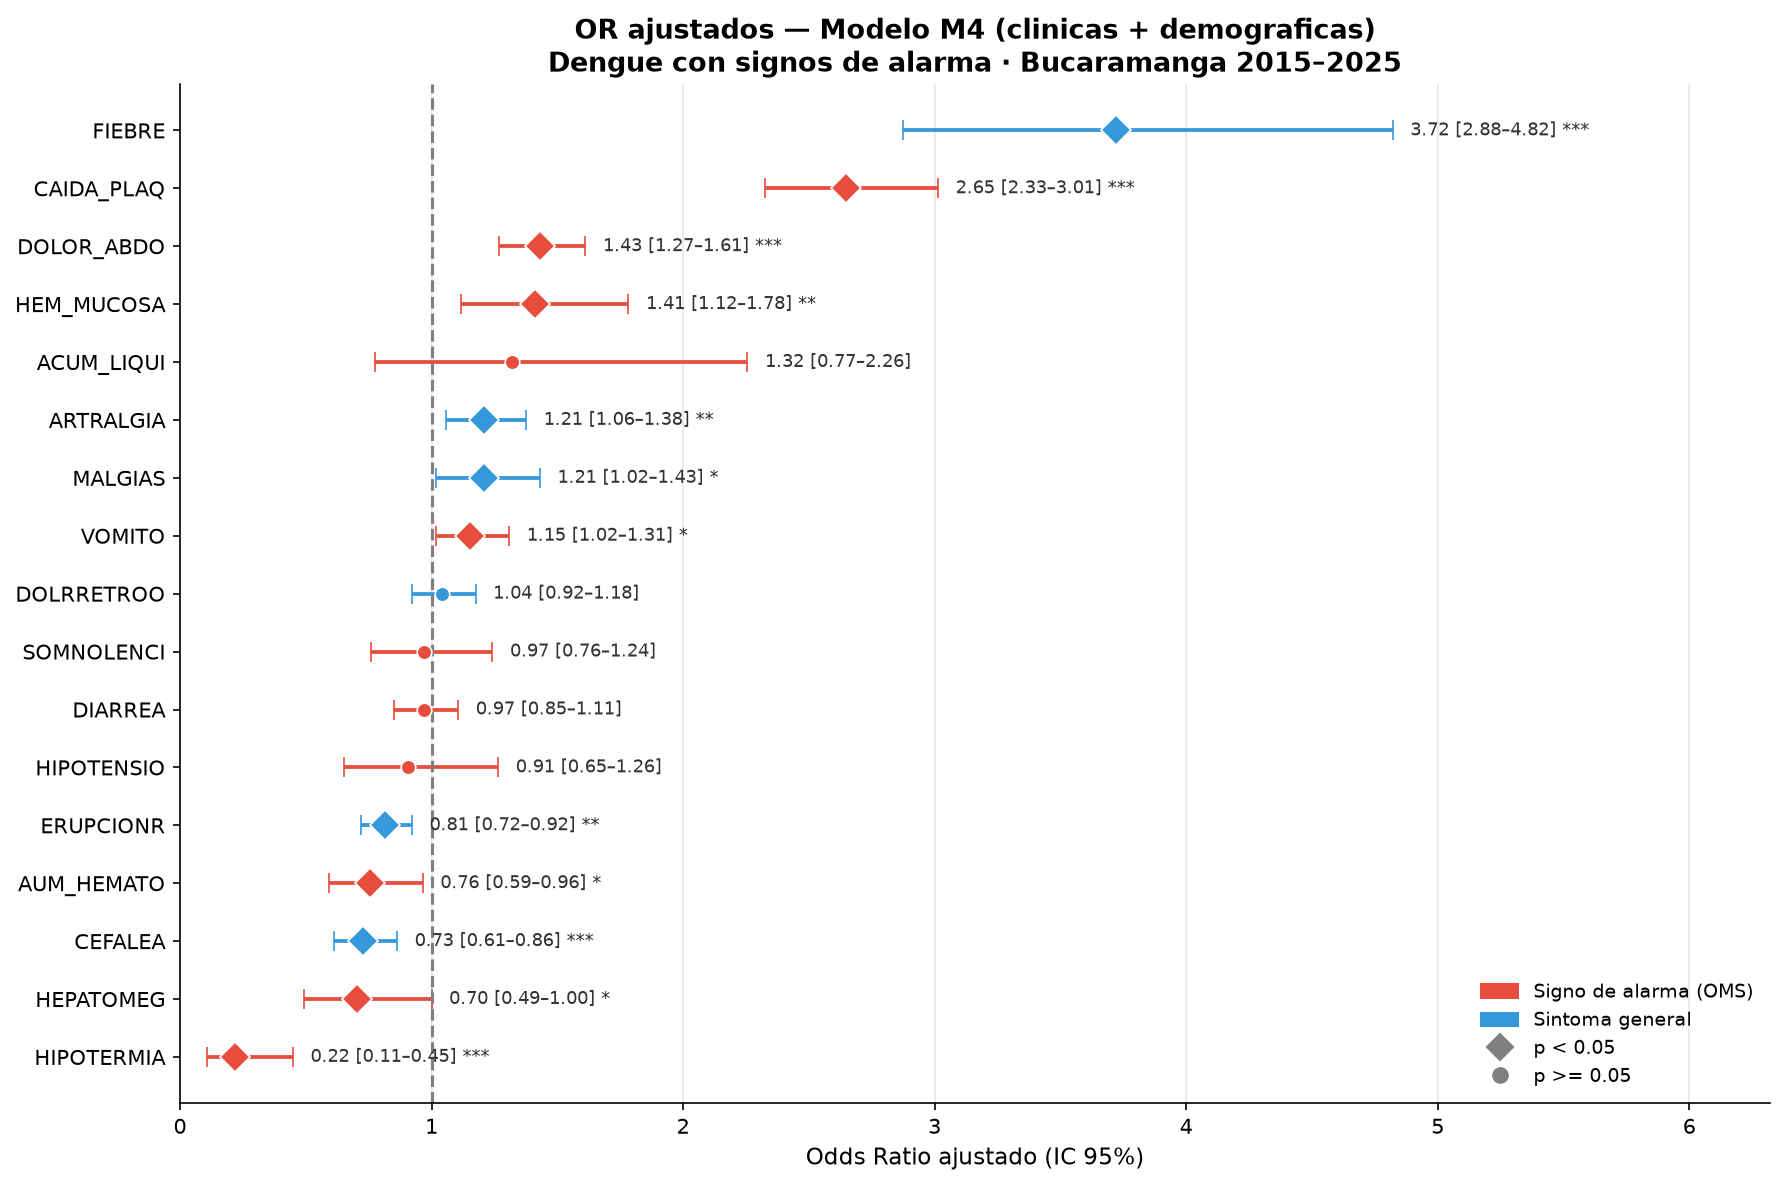

In [17]:
# Forest plot OR ajustados — Modelo M4
# Muestra la asociacion INDEPENDIENTE de cada variable clinica
# controlando por todas las demas y por factores demograficos
df_fp = tabla_or.sort_values('OR').copy()

fig, ax = plt.subplots(figsize=(12, 8))

for i, (_, f) in enumerate(df_fp.iterrows()):
    color  = COLORS['con_signos'] if f['Tipo'] == 'Signo de alarma' else COLORS['sin_signos']
    marker = 'D' if f['p_valor'] < 0.05 else 'o'
    sz     = 10 if f['p_valor'] < 0.05 else 7
    ax.errorbar(
        f['OR'], i,
        xerr=[[f['OR'] - f['IC95_inf']], [f['IC95_sup'] - f['OR']]],
        fmt=marker, capsize=5, markersize=sz, color=color,
        elinewidth=1.8, markeredgecolor='white', markeredgewidth=0.8)
    ax.text(
        f['IC95_sup'] + 0.07, i,
        f"{f['OR']:.2f} [{f['IC95_inf']:.2f}–{f['IC95_sup']:.2f}] {f['Sig']}",
        va='center', fontsize=8.5, color='#333333')

ax.set_yticks(range(len(df_fp)))
ax.set_yticklabels(df_fp['Variable'], fontsize=10)
ax.axvline(1, color=COLORS['neutral'], linestyle='--', linewidth=1.5)
ax.set_xlabel('Odds Ratio ajustado (IC 95%)')
ax.set_title(
    'OR ajustados — Modelo M4 (clinicas + demograficas)\n'
    'Dengue con signos de alarma · Bucaramanga 2015–2025')

leyenda = [
    mpatches.Patch(color=COLORS['con_signos'], label='Signo de alarma (OMS)'),
    mpatches.Patch(color=COLORS['sin_signos'], label='Sintoma general'),
    plt.Line2D([0],[0], marker='D', color='gray', markersize=9,
        linewidth=0, label='p < 0.05'),
    plt.Line2D([0],[0], marker='o', color='gray', markersize=7,
        linewidth=0, label='p >= 0.05'),
]
ax.legend(handles=leyenda, fontsize=9, loc='lower right')
ax.set_xlim(0, df_fp['IC95_sup'].max() + 1.5)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIGURES / '07_forest_OR_ajustados_M4.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [18]:
# VIF manual — sin statsmodels
# VIF > 5: colinealidad moderada; > 10: problematica
# En modelos de arboles el VIF es menos critico, pero en logistica
# infla los errores estandar y hace inestables los OR individuales
from sklearn.linear_model import LinearRegression

def vif_manual(df, variables):
    X = df[variables].apply(pd.to_numeric, errors='coerce').astype(float).dropna()
    vifs = []
    for i, col in enumerate(variables):
        otras = [v for v in variables if v != col]
        reg   = LinearRegression().fit(X[otras], X[col])
        r2    = reg.score(X[otras], X[col])
        vif   = 1 / (1 - r2) if r2 < 1 else np.inf
        vifs.append({'Variable': col, 'VIF': round(vif, 2)})
    return pd.DataFrame(vifs).sort_values('VIF', ascending=False)

vif_df = vif_manual(df_m4, todas)
vif_df['Nivel'] = pd.cut(vif_df['VIF'],
    bins=[0, 5, 10, np.inf],
    labels=['Bajo (<5)', 'Moderado (5-10)', 'Alto (>10)'])
display(vif_df)
vif_df.to_csv(OUT_TABLES / 'VIF_M4_DCSA.csv', index=False)

# Guardar resultados
joblib.dump(resultados, CHECKPOINTS / '02b_modelos_logisticos.pkl')
joblib.dump(tabla_or,   CHECKPOINTS / '02b_OR_ajustados_DCSA.pkl')
print('Checkpoints guardados')

,Variable,VIF,Nivel
0,FIEBRE,7.80,Moderado (5-10)
3,MALGIAS,3.81,Bajo (<5)
1,CEFALEA,3.02,Bajo (<5)
4,ARTRALGIA,2.12,Bajo (<5)
15,CAIDA_PLAQ,1.72,Bajo (<5)
6,DOLOR_ABDO,1.50,Bajo (<5)
2,DOLRRETROO,1.44,Bajo (<5)
7,VOMITO,1.30,Bajo (<5)
8,DIARREA,1.22,Bajo (<5)
5,ERUPCIONR,1.20,Bajo (<5)


Checkpoints guardados


## Hallazgos principales

| Variable | OR ajustado M4 | Interpretacion |
|----------|---------------|----------------|
| Caida plaquetas | ~2.7 | Mayor OR independiente |
| Fiebre | ~3.4 | VIF alto, senhal compartida |
| Dolor abdominal | ~1.4 | Asociacion robusta |
| Hemorragia mucosas | ~1.4 | Asociacion robusta |

**Siguiente:** `03_modelado/con_signos/03b_modelos_avanzados_con_signos.ipynb`